In [1]:
import sys
import os
path = os.getcwd().replace("\\notebooks", "")
sys.path.append(path)

from src.preprocessing import preprocessing

Загрузка данных

In [2]:
df = preprocessing(path + "\\data\\datasets.csv")
df

,n,text,sentiment,clean_review
0,43956,Развода на деньги нет\r\nНаблюдаюсь в Лайфклин...,1,развода на деньги нет наблюдаюсь в лайфклиник ...
1,17755,Отель выбрали потому что рядом со стадионом. О...,0,отель выбрали потому что рядом со стадионом от...
2,20269,"Вылечили\r\nГноился с рождения глазик, в полик...",1,вылечили гноился с рождения глазик в поликлини...
3,16648,Хорошее расположение.С вокзала дошли пешком.Но...,0,хорошее расположение с вокзала дошли пешком но...
4,27879,"Отличное месторасположение,прекрасный вид,особ...",1,отличное месторасположение прекрасный вид особ...
...,...,...,...,...
210984,22100,"Мой юбилей я отмечал в ресторане "" Астория "" ....",2,мой юбилей я отмечал в ресторане астория этот ...
210985,2326,"Отлично встретили, разместили в роскошном номе...",1,отлично встретили разместили в роскошном номер...
210986,10478,Была в Васаби на ст. метро Сенная . Во первых...,0,была в васаби на ст метро сенная во первых рес...
210987,4028,Ребята не стоит смотреть этот фильм. Вы молоды...,0,ребята не стоит смотреть этот фильм вы молодые...


Разделение выборки

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["sentiment"],
    test_size=0.2,
    random_state=42
)

Вес классов

In [4]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

Токенизация и последовательности

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 20000   # словарь
max_len = 200       # макс. длина отзыва

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

Модель

In [6]:
import tensorflow as tf
from tensorflow.keras import layers

model = tf.keras.Sequential([
    layers.Embedding(max_words, 128, input_length=max_len),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

c:\Users\gress\anaconda3\envs\tf\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Обучение

In [7]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1,
    class_weight=class_weights
)

Epoch 1/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 206s 343ms/step - accuracy: 0.6247 - loss: 0.7504 - val_accuracy: 0.7177 - val_loss: 0.5767
Epoch 2/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 263s 345ms/step - accuracy: 0.7615 - loss: 0.4971 - val_accuracy: 0.7365 - val_loss: 0.5651
Epoch 3/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 215s 362ms/step - accuracy: 0.7977 - loss: 0.4240 - val_accuracy: 0.7425 - val_loss: 0.5610
Epoch 4/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 255s 349ms/step - accuracy: 0.8258 - loss: 0.3636 - val_accuracy: 0.7422 - val_loss: 0.6033
Epoch 5/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 214s 360ms/step - accuracy: 0.8588 - loss: 0.3047 - val_accuracy: 0.7368 - val_loss: 0.6695


Оценка модели

In [8]:
from sklearn.metrics import classification_report

loss, acc = model.evaluate(X_test_pad, y_test)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

pred = model.predict(X_test_pad)
pred_labels = pred.argmax(axis=1)

print(classification_report(y_test, pred_labels))

1319/1319 ━━━━━━━━━━━━━━━━━━━━ 24s 18ms/step - accuracy: 0.7411 - loss: 0.6550
Test Loss: 0.6605, Test Accuracy: 0.7414
1319/1319 ━━━━━━━━━━━━━━━━━━━━ 25s 18ms/step
              precision    recall  f1-score   support

           0       0.58      0.74      0.65     10966
           1       0.85      0.71      0.77     20187
           2       0.77      0.81      0.79     11045

    accuracy                           0.74     42198
   macro avg       0.74      0.75      0.74     42198
weighted avg       0.76      0.74      0.75     42198



In [9]:
# pred = model.predict(X_test_pad)
# print(pred[:5])

Переобучение

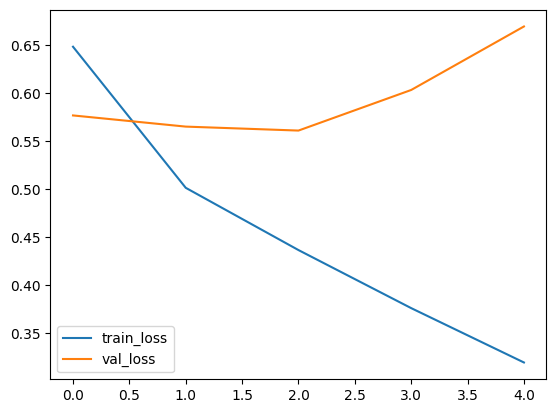

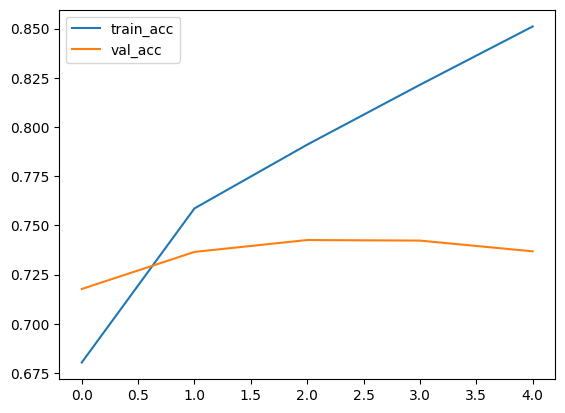

In [10]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"], label="train_acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.legend()
plt.show()

F1

In [11]:
from sklearn.metrics import f1_score, precision_score, recall_score

print("Precision macro:", precision_score(y_test, pred_labels, average="macro"))
print("Recall macro:", recall_score(y_test, pred_labels, average="macro"))
print("F1 macro:", f1_score(y_test, pred_labels, average="macro"))

print("F1 weighted:", f1_score(y_test, pred_labels, average="weighted"))

Precision macro: 0.7356800853401473
Recall macro: 0.751037006600385
F1 macro: 0.738000992413542
F1 weighted: 0.7454240335093215


Матрица ошибок

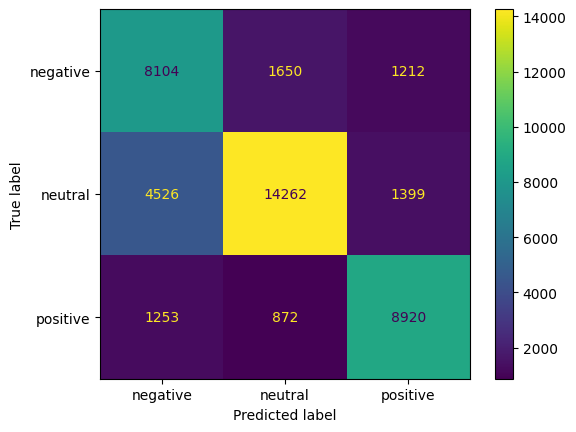

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_labels)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "neutral", "positive"]
)
disp.plot()
plt.show()

Сохранение модели

In [13]:
import pickle

model_path = os.path.join(path, "models", "sentiment_model.keras")
tokenizer_path = os.path.join(path, "models", "tokenizer.pkl")

model.save(model_path)

with open(tokenizer_path, "wb") as f:
    pickle.dump(tokenizer, f)